- entropy
- preprocesssing: picking fewer nodes (thresholding, pca) 
- agglomerative hiercharchical clustering
- 

In [2]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [3]:
%matplotlib inline
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats
from wavelet_transform.utils.bubbledynamics import BubbleDynamics as BD
from wavelet_transform.utils.label_assignment import map_labels_energy, map_labels_entropy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Set pararmeters for bubble dynamics model

In [4]:
    
def generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure):
    # generate sound wave

    BD_obj = BD(R_init, Rdot_init, frequency, pac, time, tstep)
    BD_obj.solver()
    BD_obj.calculate_p_radiated(r_measure=r_measure)

    data = BD_obj.p_radiated
    time = BD_obj.time

    return data


In [69]:
def generate_training_data(data, levels, wavelet, mode, sampling_rate, include_tr_ob = False):
    # DWPT
    tr_ob = wpt.dwpt(data, levels, wavelet, mode)
    tr_ob.calc_frequencies(sampling_rate)

    # calculate energy, kurtosis, and crest factor of reconstructed signals
    wpt_df = pd.DataFrame(
        columns=[
            "node",
            "inverse",
            "fft",
            "energy",
            "kurtosis",
            "crest",
            "entropy",
            "skewness",
        ]
    )

    total_energy = sum(node.energy for node in tr_ob.get_level(levels))
    # total_energy = stats.calc_energy(data)

    for node in tr_ob.get_level(level=levels, order="freq"):

        # calculate statistical measures
        entropy_node = stats.calc_entropy(node.energy, total_energy)
        # entropy_node = 10 ** (entropy_node)

        counter = node.node_number
        wpt_df.loc[counter, "node"] = node
        wpt_df.loc[counter, "energy"] = node.energy
        wpt_df.loc[counter, "kurtosis"] = node.kurtosis
        wpt_df.loc[counter, "crest"] = node.crest_factor
        wpt_df.loc[counter, "entropy"] = entropy_node
        wpt_df.loc[counter, "skewness"] = node.skewness


    if include_tr_ob is True:
        return wpt_df, tr_ob
    else:
        return wpt_df

In [6]:
pac = -5E5                                  # the amplitude of the sine wave in Pa
frequency = 5E5                  # insonation frequency (Hz)
no_cycle = 20                               # no. of cycles of the sine wave
sampling_rate = 500E6      # sampling rate to generate the time vector
real_sampling_rate = 50E6
tstep = 1. / sampling_rate
tmax = no_cycle / frequency
time = np.arange(0., tmax, tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.01

wavelet = "db30"
levels = 3
mode = "symmetric"

fft_lim = 10 * frequency  # increase value to view more of the fft plots

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [7]:
wpt_df = pd.DataFrame(
        columns=[
            "node",
            "inverse",
            "fft",
            "energy",
            "kurtosis",
            "crest",
            "entropy",
            "skewness",
        ]
    )

for frequency in [i * 1E5 for i in range(5, 18)]:
    for pac in [-i * 1E5 for i in range(1, 10)]:
        data = generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
        if max(data) > 100 or np.isnan(data).any():
            continue
        data = (data - np.mean(data))/np.std(data)

        # plt.plot(data)
        # plt.title(f"Frequency: {frequency}, pac: {pac}")
        # plt.show()
        step = int(sampling_rate/real_sampling_rate)
        training_data = generate_training_data(
            data[::step], levels, wavelet, mode, sampling_rate=real_sampling_rate
        )
        wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)


### Training

Train fuzzy c-means on the generated data

In [49]:
from sklearn.preprocessing import StandardScaler
import skfuzzy as fuzz

# get data. first entry must be 'energy' or 'entropy'
classifying_metrics = ["energy", "kurtosis", "crest"]
data_train = wpt_df[classifying_metrics]

# standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# parameters for Fuzzy C-means
no_clusters = 4
m = 1.2
error = 1e-6

# Fuzzy C-Means clustering
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data_train_normalised.T,
    c=no_clusters,
    m=m,
    error=error,
    maxiter=100,
)
print("number of iterations:", p)
# cluster centres
centers = scaler.inverse_transform(cntr)
print("centers:", centers)
# membership matrix
membership_matrix = u.T

# hard cluster assignments
labels = np.argmax(membership_matrix, axis=1)
for i in range(no_clusters):
    print(f"label {i} count:", list(labels).count(i))

# membership_results = pd.DataFrame()
# for i, membership in enumerate(membership_matrix):
#     membership_results.loc[i, "hard assignment"] = labels[i]
#     for j in range(no_clusters):
#         membership_results.loc[i, f"membership {j}"] = membership[j]

# membership_results.head()

number of iterations: 60
centers: [[ 2.24103612e-01  6.72512714e+01  8.40799849e+00]
 [ 1.79485284e-01  2.88044013e+01  5.55203105e+00]
 [ 7.00277715e+00  2.29548173e+00 -4.49388866e+00]
 [ 5.41962246e-02  4.60421612e+00 -8.77461179e-01]]
label 0 count: 104
label 1 count: 279
label 2 count: 113
label 3 count: 440


### Reassigning labels

Post-hoc assignment of labels

In [50]:
if classifying_metrics[0] == "energy":
    mapping = map_labels_energy(centers)
elif classifying_metrics[0] == "entropy":
    mapping = map_labels_entropy(centers)
# print("centre number: new label")
# print(mapping)
# print(centers)

Hard assignments

In [51]:
def reassign_labels(mapping, labels):
    # reassigning labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

reassigned_labels = reassign_labels(mapping, labels)
print(reassigned_labels)
for i in range(1, no_clusters + 1):
    print(f"label {i} count:", list(reassigned_labels).count(i))

[4, 2, 1, 1, 1, 1, 1, 1, 4, 2, 1, 2, 2, 1, 1, 1, 4, 2, 2, 3, 3, 3, 2, 3, 4, 1, 2, 2, 2, 2, 2, 2, 4, 2, 2, 2, 2, 3, 2, 3, 2, 2, 3, 3, 3, 3, 2, 3, 4, 2, 3, 3, 3, 2, 2, 3, 1, 2, 3, 2, 2, 3, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 4, 3, 1, 1, 1, 1, 1, 1, 4, 1, 2, 2, 3, 3, 2, 2, 4, 1, 2, 2, 2, 2, 2, 2, 4, 1, 3, 2, 2, 3, 2, 3, 4, 2, 3, 3, 3, 3, 3, 3, 4, 1, 3, 2, 2, 3, 2, 2, 4, 2, 2, 2, 2, 1, 1, 2, 4, 2, 2, 3, 2, 2, 2, 2, 4, 2, 3, 3, 3, 2, 2, 3, 4, 3, 1, 1, 1, 1, 1, 1, 4, 1, 2, 1, 1, 1, 1, 1, 4, 1, 3, 2, 1, 1, 1, 1, 4, 3, 3, 3, 3, 3, 3, 3, 4, 2, 2, 3, 2, 2, 2, 3, 4, 1, 2, 2, 2, 2, 2, 2, 4, 1, 2, 2, 2, 2, 2, 2, 4, 2, 3, 3, 2, 2, 2, 3, 4, 1, 3, 3, 2, 3, 2, 2, 4, 2, 1, 1, 1, 1, 1, 1, 4, 3, 1, 1, 1, 1, 1, 1, 4, 2, 1, 1, 1, 1, 1, 2, 4, 1, 2, 2, 2, 2, 2, 2, 4, 1, 3, 3, 2, 3, 2, 3, 4, 1, 2, 2, 2, 2, 2, 2, 4, 1, 2, 2, 2, 2, 2, 2, 4, 2, 2, 2, 2, 2, 2, 2, 4, 1, 2, 2, 2, 2, 2, 2, 4, 2, 1, 1, 1, 1, 1, 1, 4, 2, 2, 1, 1, 1, 1, 1, 4, 3, 1, 1, 1, 1, 1, 1, 4, 2, 3, 3, 3, 2, 2, 2, 4, 1, 3, 2, 1, 2, 1, 1, 4, 2, 2, 1, 1, 

Plotting clustering results

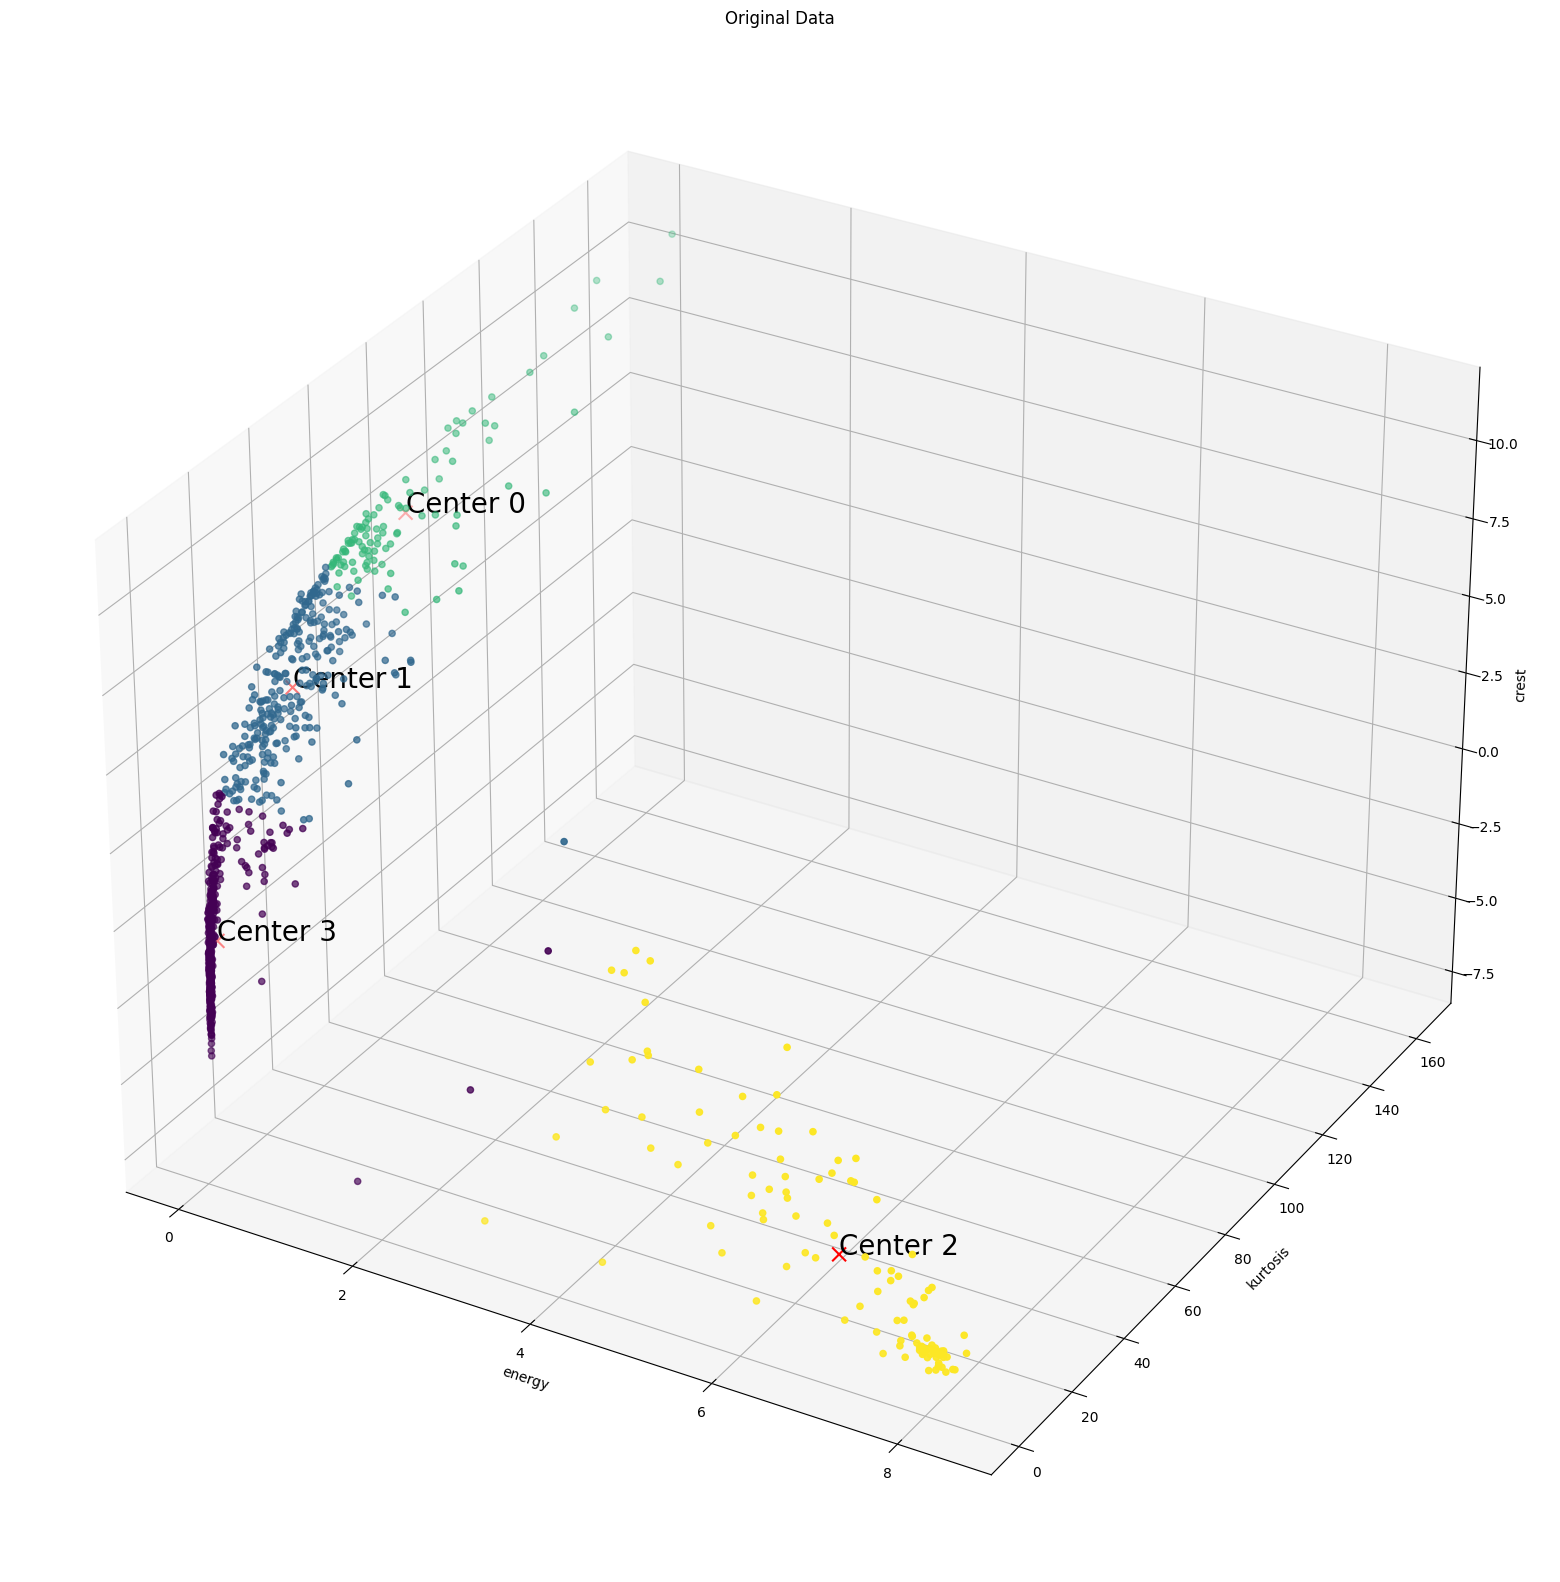

In [52]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
color_map_labels = reassigned_labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

# Annotate cluster centers with their positions
for i, center in enumerate(centers_scatter):
    ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

plt.show()



### Classifying new data points

dynamics is inconsistent
clustering works better with fewer levels
need better standardisation of data

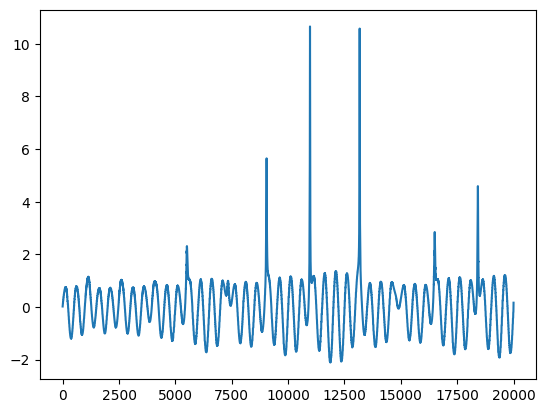

In [79]:
frequency = 10E5
pac = -5E5

data = generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
data = (data - np.mean(data)) / np.std(data)
new_wpt_df, new_tr_ob = generate_training_data(
    data[::step], 
    levels,
    wavelet, 
    mode, 
    sampling_rate=real_sampling_rate,
    include_tr_ob=True  # return transform object for inverse
)

new_wpt_df.head()

plt.plot(data)
plt.show()

In [80]:
# New testing data from signal
new_entry = new_wpt_df[classifying_metrics]

# Standardize the new entry using the same scaler
new_entry_normalized = scaler.transform(new_entry)

# Predict membership using the cluster centers and membership matrix
new_u, *_ = fuzz.cluster.cmeans_predict(
    new_entry_normalized.T,
    cntr,
    m=m,
    error=error,
    maxiter=100,
)

new_membership_matrix = new_u.T
# Convert membership to hard cluster assignment
new_labels = np.argmax(new_u, axis=0)

# Display the predicted results
print("Predicted hard cluster assignment:", new_labels)

# membership_results = pd.DataFrame()
# for i, membership in enumerate(new_membership_matrix):
#     membership_results.loc[i, "hard assignment"] = new_labels[i]
#     for j in range(no_clusters):
#         membership_results.loc[i, f"membership {j}"] = membership[j]

# membership_results

Predicted hard cluster assignment: [2 3 1 0 1 1 1 0]


In [81]:
# reassigning labels
new_reassigned_labels = reassign_labels(mapping, new_labels)
print(new_reassigned_labels)
# for i in range(1, no_clusters + 1):
    # print(f"label {i} count:", list(new_reassigned_labels).count(i))

[4, 1, 2, 3, 2, 2, 2, 3]


### Reconstructing by cluster

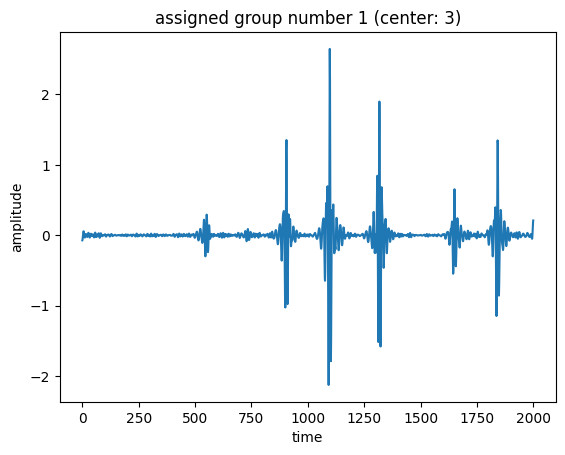

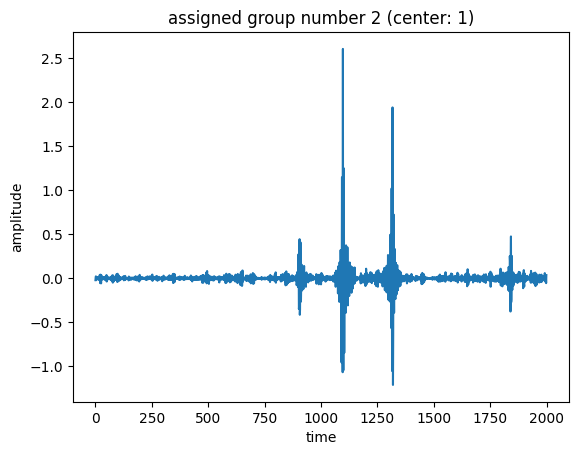

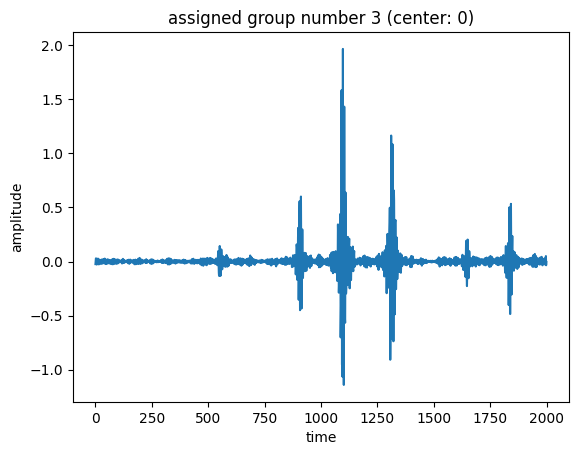

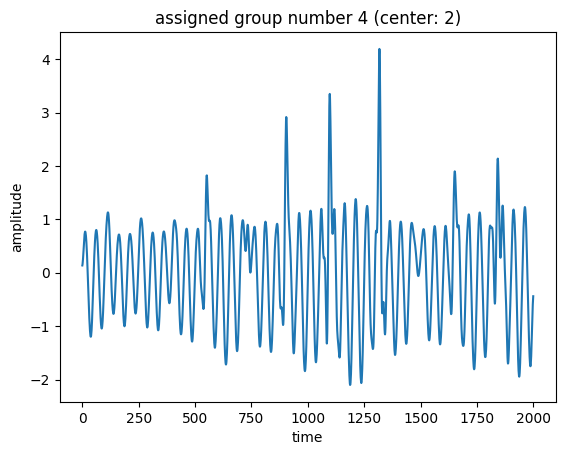

In [82]:
rec_signal = inv.inv_dwpt(new_tr_ob, level=levels)

reconstructions = [np.zeros(len(rec_signal)) for _ in range(no_clusters)]

for node, assignment in zip(new_tr_ob.get_level(), new_reassigned_labels):
    rec_signal = inv.inv_dwpt(new_tr_ob, level=levels, nodes=node)
    i = assignment - 1
    reconstructions[i] = reconstructions[i] + rec_signal

for i in range(no_clusters):
    plt.plot(reconstructions[i])
    center = [c for c in mapping if mapping[c] == i + 1][0]
    plt.title(f"assigned group number {i+1} (center: {center})")
    plt.xlabel("time")
    plt.ylabel("amplitude")
    plt.show()

## Soft assignments

In [83]:
def generate_soft_assignments(mapping, membership_matrix):
    soft_assignments = [
        sum([mapping[i] * weight for i, weight in enumerate(membership)])
        for membership in membership_matrix
    ]
    return soft_assignments

[3.999999999994738, 2.4972701072565244, 1.0000003515595528, 1.0000000060603877, 1.0000000000076752, 1.208923847063596, 1.0000000031441443, 1.0, 3.9999998497425087, 1.9999841670849952, 1.44831926164741, 1.9970345545021884, 1.8970635443592692, 1.000056986914809, 1.0000023204337054, 1.0000000008516317, 3.072523715296773, 1.997356939335352, 1.9999999892350477, 2.999998320461163, 2.999818916010343, 2.9999930399055854, 2.0000000000050058, 2.9999927203946304, 3.773060794780441, 1.2831651204980516, 1.99999918622219, 1.9999999999996307, 2.0000011770578707, 2.000155358436621, 1.9965179757448128, 2.000000000000016, 3.8135765369542245, 1.999992782818618, 2.00003100033024, 2.2327346314801835, 2.000000000764848, 2.999140985131633, 1.9999999990994657, 2.999999443492306, 1.91079650751611, 2.000021399638518, 2.9998669685654566, 2.9993487019099856, 2.7927399609042487, 2.99999869587367, 2.1720333527907876, 2.9999999466855476, 3.15310693359454, 2.000106166744453, 2.9999885327605327, 2.999998498322103, 2.9

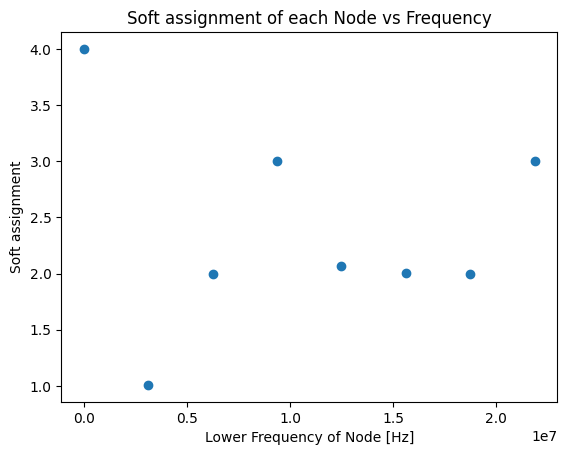

In [84]:
new_soft_assignments = generate_soft_assignments(mapping, new_membership_matrix)
print(soft_assignments)
### Plotting new assignments
# plot weighted reassigned labels
plt.scatter([node.frequency_range[0] for node in new_wpt_df["node"]], new_soft_assignments)
plt.title("Soft assignment of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Soft assignment")
plt.show()

### Soft assignments for the whole dataset

[3.999999999994738, 2.4972701072565244, 1.0000003515595528, 1.0000000060603877, 1.0000000000076752, 1.208923847063596, 1.0000000031441443, 1.0, 3.9999998497425087, 1.9999841670849952, 1.44831926164741, 1.9970345545021884, 1.8970635443592692, 1.000056986914809, 1.0000023204337054, 1.0000000008516317, 3.072523715296773, 1.997356939335352, 1.9999999892350477, 2.999998320461163, 2.999818916010343, 2.9999930399055854, 2.0000000000050058, 2.9999927203946304, 3.773060794780441, 1.2831651204980516, 1.99999918622219, 1.9999999999996307, 2.0000011770578707, 2.000155358436621, 1.9965179757448128, 2.000000000000016, 3.8135765369542245, 1.999992782818618, 2.00003100033024, 2.2327346314801835, 2.000000000764848, 2.999140985131633, 1.9999999990994657, 2.999999443492306, 1.91079650751611, 2.000021399638518, 2.9998669685654566, 2.9993487019099856, 2.7927399609042487, 2.99999869587367, 2.1720333527907876, 2.9999999466855476, 3.15310693359454, 2.000106166744453, 2.9999885327605327, 2.999998498322103, 2.9

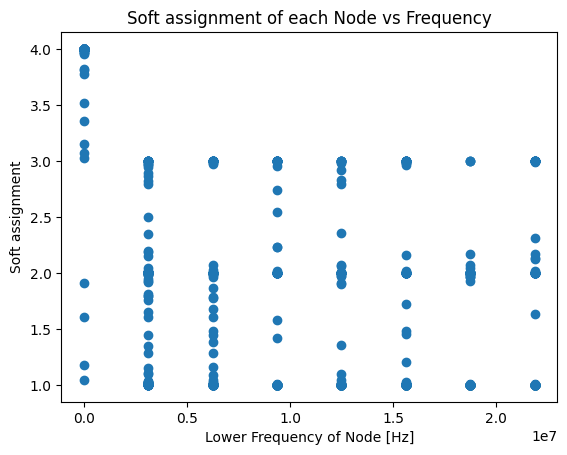

In [85]:
soft_assignments = generate_soft_assignments(mapping, membership_matrix)
print(soft_assignments)

# plot weighted reassigned labels
plt.scatter([node.frequency_range[0] for node in wpt_df["node"]], soft_assignments)
plt.title("Soft assignment of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Soft assignment")
plt.show()